# Fasl · Notebook 2: Train the wheat models
Trains two image classifiers on the clean data from Notebook 1 (`fasl-clean`):
- **Health model** (8 classes): healthy, brown_rust, yellow_rust, stem_rust, septoria, loose_smut, powdery_mildew, **not_wheat**
- **Stage model** (4 classes): vegetative, flowering, grain_filling, ripening

Both use EfficientNet-B0 pretrained on ImageNet. At the end both are packed into **one ONNX file** for the API, and all real test numbers are written to `metrics.json` for the website.

**Settings before running:** Accelerator **GPU T4 x2** (or P100), Internet **On**, input dataset `fasl-clean` attached.

## Step 1: Setup
Imports, settings and the GPU check. Also finds the `fasl-clean` dataset automatically.

In [1]:
import os, json, time, random, math, copy
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

INPUT_ROOT = Path(os.getenv("FASL_INPUT", "/kaggle/input"))
OUT = Path(os.getenv("FASL_OUT", "/kaggle/working/model"))
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
IMG = 224
BATCH = 32
WORKERS = 2
ARCH = "efficientnet_b0"
PRETRAINED = os.getenv("FASL_PRETRAINED", "1") == "1"
EPOCHS = {"health": int(os.getenv("FASL_EPOCHS_H", 15)), "stage": int(os.getenv("FASL_EPOCHS_S", 25))}
LR = 3e-4
PATIENCE = 8            # stop if val macro-F1 does not improve for this many epochs
MODEL_VERSION = "fasl-wheat-v0.1"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

manifests = sorted(INPUT_ROOT.rglob("manifest.csv"))
assert manifests, "fasl-clean not attached: no manifest.csv under /kaggle/input"
DATA = manifests[0].parent
man = pd.read_csv(DATA / "manifest.csv")
print("Data folder:", DATA, "| images:", len(man))
print(pd.crosstab([man.task, man.label], man.split).to_string())

Device: cuda Tesla T4
Data folder: /kaggle/input/notebooks/hashirsakimdad/01-collect-and-clean/fasl_clean | images: 10446
split                     test  train  val
task      label                           
health    brown_rust       169    791  169
          healthy          364   1701  365
          loose_smut        39    182   39
          powdery_mildew   124    581  124
          septoria          66    313   67
          stem_rust         45    210   45
          yellow_rust      463   2161  463
not_wheat not_wheat        221   1034  222
stage     flowering          9     45    9
          grain_filling     26    125   27
          ripening          34    160   34
          vegetative         2     14    3


## Step 2: Build the two training tables
- Health model: all `health` images plus `not_wheat` (so it can reject non-wheat photos).
- Stage model: all `stage` images.

In [2]:
HEALTH = ["healthy","brown_rust","yellow_rust","stem_rust","septoria","loose_smut","powdery_mildew","not_wheat"]
STAGE = ["vegetative","flowering","grain_filling","ripening"]
TASKS = {
    "health": (man[man.task.isin(["health","not_wheat"])].copy(), HEALTH),
    "stage":  (man[man.task == "stage"].copy(), STAGE),
}
for name, (d, labels) in TASKS.items():
    labels[:] = [l for l in labels if l in set(d.label)]     # drop classes with no images
    d["y"] = d.label.map({l: i for i, l in enumerate(labels)})
    print(name, "classes:", labels, "| train/val/test:", [int((d.split == s).sum()) for s in ["train","val","test"]])

health classes: ['healthy', 'brown_rust', 'yellow_rust', 'stem_rust', 'septoria', 'loose_smut', 'powdery_mildew', 'not_wheat'] | train/val/test: [6973, 1494, 1491]
stage classes: ['vegetative', 'flowering', 'grain_filling', 'ripening'] | train/val/test: [344, 73, 71]


## Step 3: Image loading and augmentation
- **Pad to square** first, so long thin leaf photos are not stretched. The API does exactly the same.
- Training images get random crops, flips, rotation and colour changes so the model copes with real phone photos.

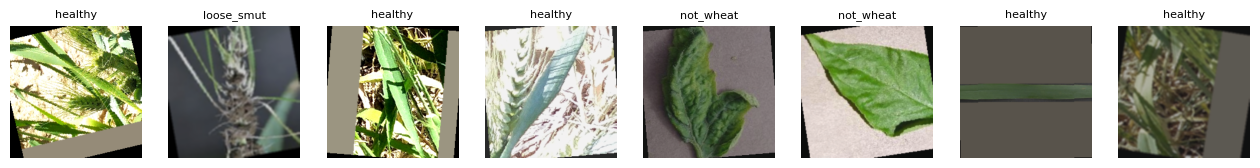

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def pad_square(img):
    w, h = img.size; s = max(w, h)
    canvas = Image.new("RGB", (s, s), tuple(int(m * 255) for m in MEAN))
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas

train_tf = T.Compose([
    T.Lambda(pad_square),
    T.RandomResizedCrop(IMG, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(15),
    T.ColorJitter(0.3, 0.3, 0.2, 0.03),
    T.RandomApply([T.GaussianBlur(5)], p=0.15),
    T.ToTensor(), T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Lambda(pad_square), T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])

class ImgDS(Dataset):
    def __init__(self, d, tf): self.p, self.y, self.tf = list(d.path), list(d.y), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        img = Image.open(DATA / self.p[i]).convert("RGB")
        return self.tf(img), self.y[i]

def loaders(d):
    mk = lambda s, tf, sh: DataLoader(ImgDS(d[d.split == s], tf), batch_size=BATCH, shuffle=sh,
                                      num_workers=WORKERS, pin_memory=DEVICE == "cuda")
    return mk("train", train_tf, True), mk("val", eval_tf, False), mk("test", eval_tf, False)

# preview a few augmented training images
d, labels = TASKS["health"]
ds = ImgDS(d[d.split == "train"].sample(8, random_state=SEED), train_tf)
fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
for a, (x, y) in zip(ax, [ds[i] for i in range(8)]):
    a.imshow((x.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)); a.set_title(labels[y], fontsize=8); a.axis("off")
plt.show()

## Step 4: Training function
- Class weights: rare classes (loose_smut, stem_rust) count more in the loss, so the model does not ignore them.
- Mixed precision on GPU for speed, cosine learning-rate schedule.
- Keeps the epoch with the best **validation macro-F1** and stops early if it stops improving.

In [4]:
def run_epoch(model, dl, crit, opt=None, scaler=None):
    train = opt is not None
    model.train(train); total, ys, ps = 0.0, [], []
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            out = model(x); loss = crit(out, y)
        if train:
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        total += loss.item() * len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return total / len(dl.dataset), accuracy_score(ys, ps), f1_score(ys, ps, average="macro")

def train_task(name):
    d, labels = TASKS[name]
    tr, va, te = loaders(d)
    counts = np.bincount(d[d.split == "train"].y, minlength=len(labels))
    w = (1.0 / np.maximum(counts, 1)) ** 0.5
    w = torch.tensor(w / w.sum() * len(w), dtype=torch.float32)
    crit = nn.CrossEntropyLoss(weight=w.to(DEVICE), label_smoothing=0.1)

    model = timm.create_model(ARCH, pretrained=PRETRAINED, num_classes=len(labels)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS[name])
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")

    hist, best, best_state, wait = [], -1, None, 0
    for ep in range(1, EPOCHS[name] + 1):
        t = time.time()
        tl, ta, tf1 = run_epoch(model, tr, crit, opt, scaler)
        vl, vacc, vf1 = run_epoch(model, va, crit)
        sched.step()
        hist.append(dict(epoch=ep, train_loss=round(tl, 4), val_loss=round(vl, 4), train_acc=round(ta, 4),
                         val_acc=round(vacc, 4), val_macro_f1=round(vf1, 4)))
        print(f"[{name}] ep {ep:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {vacc:.3f} F1 {vf1:.3f} | {time.time()-t:.0f}s")
        if vf1 > best: best, best_state, wait = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE: print("early stop"); break
    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{name}.pt")
    return model, hist, te, labels

## Step 5: Train the health model
About 10 to 20 minutes on a T4 GPU.

In [5]:
health_model, health_hist, health_test, health_labels = train_task("health")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[health] ep  1 | train loss 1.368 acc 0.783 | val loss 0.972 acc 0.908 F1 0.845 | 259s
[health] ep  2 | train loss 0.879 acc 0.928 | val loss 0.849 acc 0.952 F1 0.908 | 49s
[health] ep  3 | train loss 0.793 acc 0.958 | val loss 0.783 acc 0.964 F1 0.926 | 48s
[health] ep  4 | train loss 0.752 acc 0.969 | val loss 0.794 acc 0.961 F1 0.919 | 50s
[health] ep  5 | train loss 0.728 acc 0.975 | val loss 0.755 acc 0.970 F1 0.935 | 49s
[health] ep  6 | train loss 0.704 acc 0.983 | val loss 0.744 acc 0.968 F1 0.931 | 49s
[health] ep  7 | train loss 0.691 acc 0.987 | val loss 0.742 acc 0.970 F1 0.940 | 49s
[health] ep  8 | train loss 0.681 acc 0.990 | val loss 0.729 acc 0.975 F1 0.950 | 49s
[health] ep  9 | train loss 0.671 acc 0.992 | val loss 0.726 acc 0.971 F1 0.940 | 50s
[health] ep 10 | train loss 0.666 acc 0.993 | val loss 0.726 acc 0.973 F1 0.942 | 49s
[health] ep 11 | train loss 0.662 acc 0.993 | val loss 0.720 acc 0.977 F1 0.949 | 50s
[health] ep 12 | train loss 0.656 acc 0.996 | val los

## Step 6: Train the stage model
Small dataset (under 500 images), so this is quick but its test score is less reliable. Treat it as a first version.

In [6]:
stage_model, stage_hist, stage_test, stage_labels = train_task("stage")

[stage] ep  1 | train loss 2.939 acc 0.436 | val loss 1.777 acc 0.781 F1 0.718 | 15s
[stage] ep  2 | train loss 1.509 acc 0.762 | val loss 1.743 acc 0.726 F1 0.618 | 3s
[stage] ep  3 | train loss 1.352 acc 0.814 | val loss 1.540 acc 0.712 F1 0.615 | 3s
[stage] ep  4 | train loss 1.129 acc 0.811 | val loss 1.294 acc 0.685 F1 0.610 | 3s
[stage] ep  5 | train loss 1.053 acc 0.855 | val loss 1.452 acc 0.616 F1 0.573 | 3s
[stage] ep  6 | train loss 1.171 acc 0.820 | val loss 1.136 acc 0.726 F1 0.676 | 3s
[stage] ep  7 | train loss 1.034 acc 0.820 | val loss 1.550 acc 0.575 F1 0.588 | 3s
[stage] ep  8 | train loss 0.941 acc 0.887 | val loss 1.213 acc 0.671 F1 0.634 | 3s
[stage] ep  9 | train loss 0.947 acc 0.898 | val loss 1.135 acc 0.658 F1 0.602 | 3s
early stop


## Step 7: Evaluate on the test set
The test set was never used for training or for picking the best epoch, so these are the honest numbers.
Shows per-class precision / recall / F1 and a confusion matrix for each model.


== health: accuracy 0.971 | macro-F1 0.946 | 1491 test images
         label  precision  recall     f1  support
       healthy     0.9700  0.9780 0.9740      364
    brown_rust     0.9756  0.9467 0.9610      169
   yellow_rust     0.9806  0.9849 0.9828      463
     stem_rust     0.8000  0.8000 0.8000       45
      septoria     0.9286  0.9848 0.9559       66
    loose_smut     0.9250  0.9487 0.9367       39
powdery_mildew     0.9748  0.9355 0.9547      124
     not_wheat     1.0000  1.0000 1.0000      221


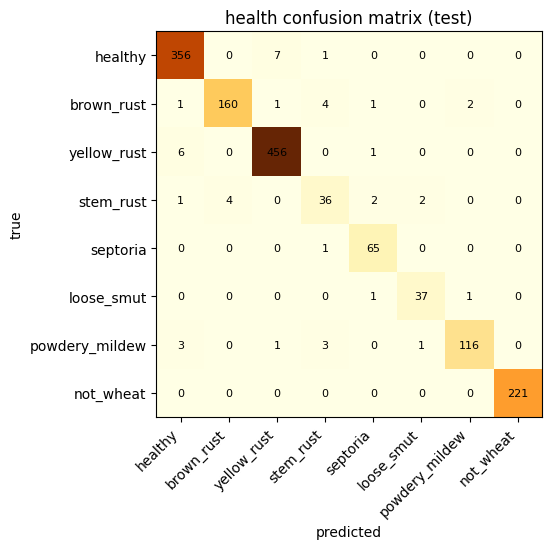


== stage: accuracy 0.747 | macro-F1 0.605 | 71 test images
        label  precision  recall     f1  support
   vegetative     0.1000  0.5000 0.1667        2
    flowering     0.6250  0.5556 0.5882        9
grain_filling     0.7931  0.8846 0.8364       26
     ripening     1.0000  0.7059 0.8276       34


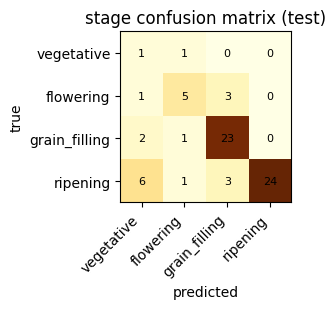

In [7]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); ys, ps = [], []
    for x, y in dl:
        ps += model(x.to(DEVICE)).argmax(1).tolist(); ys += y.tolist()
    return np.array(ys), np.array(ps)

def evaluate(name, model, dl, labels):
    y, p = predict(model, dl)
    idx = list(range(len(labels)))
    pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=idx, zero_division=0)
    cm = confusion_matrix(y, p, labels=idx)
    res = {
        "accuracy": round(float(accuracy_score(y, p)), 4),
        "macro_f1": round(float(f1_score(y, p, labels=idx, average="macro", zero_division=0)), 4),
        "test_images": int(len(y)),
        "labels": labels,
        "per_class": [dict(label=l, precision=round(float(a), 4), recall=round(float(b), 4), f1=round(float(c), 4), support=int(s))
                      for l, a, b, c, s in zip(labels, pr, rc, f1, sup)],
        "confusion_matrix": cm.tolist(),
    }
    print(f"\n== {name}: accuracy {res['accuracy']:.3f} | macro-F1 {res['macro_f1']:.3f} | {len(y)} test images")
    print(pd.DataFrame(res["per_class"]).to_string(index=False))
    fig, ax = plt.subplots(figsize=(1 + 0.7 * len(labels), 0.8 + 0.6 * len(labels)))
    ax.imshow(cm, cmap="YlOrBr")
    ax.set_xticks(idx, labels, rotation=45, ha="right"); ax.set_yticks(idx, labels)
    for i in idx:
        for j in idx: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{name} confusion matrix (test)")
    plt.tight_layout(); plt.show()
    return res

health_res = evaluate("health", health_model, health_test, health_labels)
stage_res = evaluate("stage", stage_model, stage_test, stage_labels)

## Step 8: Training curves
Validation macro-F1 and loss per epoch. Train and validation lines far apart = overfitting.

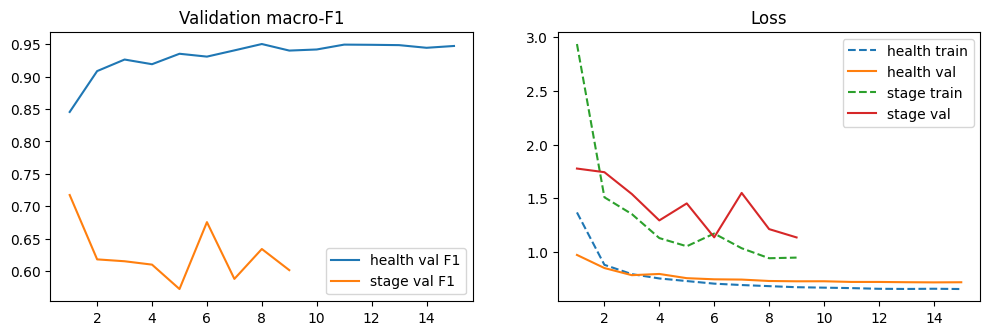

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, h in [("health", health_hist), ("stage", stage_hist)]:
    h = pd.DataFrame(h)
    ax[0].plot(h.epoch, h.val_macro_f1, label=f"{name} val F1")
    ax[1].plot(h.epoch, h.train_loss, "--", label=f"{name} train"); ax[1].plot(h.epoch, h.val_loss, label=f"{name} val")
ax[0].set_title("Validation macro-F1"); ax[1].set_title("Loss"); ax[0].legend(); ax[1].legend()
plt.show()

## Step 9: Export one ONNX file for the API
Packs both models into `fasl_wheat.onnx`:
- input `image`: float32 `[N, 3, 224, 224]`, padded to square, ImageNet-normalised
- outputs `stage` and `health`: raw scores (logits)

Then checks the ONNX output matches PyTorch.

In [9]:
!pip install -q onnx onnxruntime
import onnxruntime as ort

In [10]:
import onnxruntime as ort

class Combined(nn.Module):
    def __init__(self, stage, health):
        super().__init__(); self.stage, self.health = stage, health
    def forward(self, image): return self.stage(image), self.health(image)

combo = Combined(copy.deepcopy(stage_model).float().cpu(), copy.deepcopy(health_model).float().cpu()).eval()
dummy = torch.randn(1, 3, IMG, IMG)
onnx_path = OUT / "fasl_wheat.onnx"
torch.onnx.export(combo, dummy, onnx_path, input_names=["image"], output_names=["stage", "health"],
                  dynamic_axes={"image": {0: "n"}, "stage": {0: "n"}, "health": {0: "n"}}, opset_version=17, dynamo=False)

combo.eval()
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
x = torch.randn(4, 3, IMG, IMG)
with torch.no_grad(): ts, th = combo(x)
os_, oh = sess.run(["stage", "health"], {"image": x.numpy()})
print("max diff stage:", float(np.abs(ts.numpy() - os_).max()), "| health:", float(np.abs(th.numpy() - oh).max()))
print("ONNX size:", round(onnx_path.stat().st_size / 1e6, 1), "MB")

t = time.time()
for _ in range(20): sess.run(None, {"image": x[:1].numpy()})
infer_ms = round((time.time() - t) / 20 * 1000, 1)
print("CPU inference per image:", infer_ms, "ms")

/tmp/ipykernel_23/1975193602.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(combo, dummy, onnx_path, input_names=["image"], output_names=["stage", "health"],


max diff stage: 2.2411346435546875e-05 | health: 2.8133392333984375e-05
ONNX size: 32.1 MB
CPU inference per image: 18.4 ms


## Step 10: Write `metrics.json` and `labels.json`
- `metrics.json` goes to the website (`public/metrics.json`). Every number in it comes from this run.
- `labels.json` goes to the API (`ml/config/labels.json`) so class order matches the model.

In [11]:
counts = lambda name: {s: int((TASKS[name][0].split == s).sum()) for s in ["train", "val", "test"]}
metrics = {
    "model_version": MODEL_VERSION,
    "architecture": ARCH,
    "image_size": IMG,
    "dataset": {"health": counts("health"), "stage": counts("stage"),
                "sources": sorted(man.source.unique().tolist())},
    "heads": {"health": health_res, "stage": stage_res},
    "training_curve": {"health": health_hist, "stage": stage_hist},
    "inference_ms_cpu": infer_ms,
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
labels_cfg = {"crop": "wheat", "model_version": MODEL_VERSION, "image_size": IMG, "mean": MEAN, "std": STD,
              "growth_stage": stage_labels, "health": health_labels, "confidence_threshold": 0.6}
(OUT / "labels.json").write_text(json.dumps(labels_cfg, indent=2))
print(json.dumps({k: metrics["heads"][k]["accuracy"] for k in metrics["heads"]}, indent=2))
print("Saved:", sorted(p.name for p in OUT.iterdir()))

{
  "health": 0.9705,
  "stage": 0.7465
}
Saved: ['fasl_wheat.onnx', 'health.pt', 'labels.json', 'metrics.json', 'stage.pt']


## Step 11: Next
1. **Save Version → Save & Run All (Commit)** with GPU on.
2. Open the version → **Output** → download `fasl_wheat.onnx`, `metrics.json`, `labels.json`.
3. Send me the numbers printed in Step 7, and we will decide what to improve (more stage data, more epochs, a bigger model).